# 03 · Mecanismo del alelo missense — estructura y conservación

> **Saneado:** sin posición ni identidad de aminoácidos. El residuo se nombra por su papel.
>
> **Regla congelada antes de mirar:** la conservación pertenece a la **historia mecanística**,
> no a la clasificación. `PP3` tuvo su turno preregistrado con REVEL y volvió indeterminado.
> Nada de este notebook lo reabre.

## Pregunta biológica

El missense está en VUS y no se mueve por clasificación. **¿Se mueve por mecanismo?**

Importa porque `BUBR1` es una **pseudoquinasa**: la actividad catalítica es prescindible, y
los residuos que en quinasas convencionales unen ATP aquí sirven a la **estabilidad
conformacional**. La pregunta correcta no es «¿pierde catálisis?» sino «¿queda menos
proteína?».

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


## QC · ¿es fiable el modelo en esa región?

Sin esto, medir enterramiento o contactos no significaría nada. **Uso permitido de pLDDT:**
evaluar si el modelo es fiable ahí. **Uso prohibido:** comparar pLDDT silvestre frente a
mutante como evidencia de desestabilización — el brief lo veta, porque ΔpLDDT correlaciona
muy débilmente con ΔΔG.

In [2]:
d = json.load(io.open("work/struct/fig4.json", encoding="utf-8"))
prof = np.array([p[1] for p in d["plddt_profile"]])
t = d["plddt_target"]
print(f"  pLDDT en el residuo candidato : {t}")
print(f"  media de toda la proteina     : {prof.mean():.1f}")
print(f"  percentil del candidato       : {100*(prof < t).mean():.0f}")
print(f"  RSA relativa                  : {d['rsa']} %   (< 20 % = enterrado)")

  pLDDT en el residuo candidato : 91.1
  media de toda la proteina     : 63.6
  percentil del candidato       : 88
  RSA relativa                  : 16.2 %   (< 20 % = enterrado)


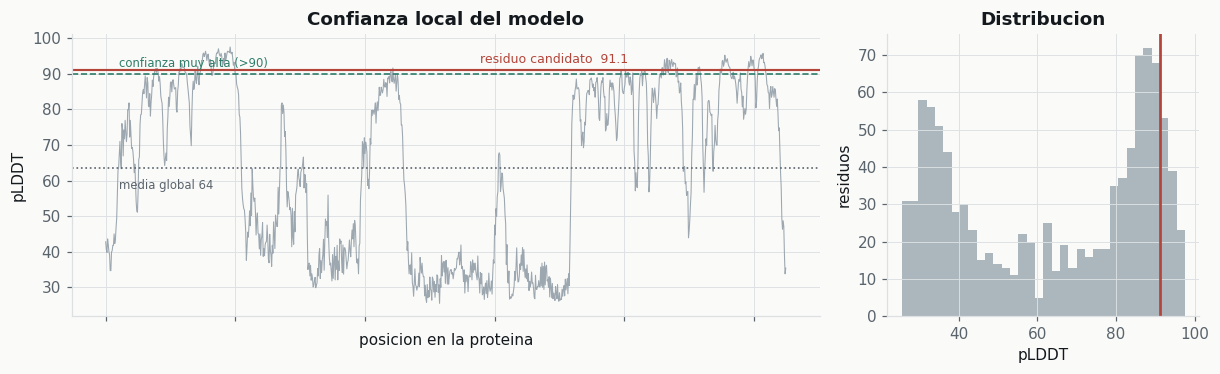

> **Figura QC · el modelo es fiable donde importa**  
> `EXP-010` · **PREDICTED**  
> *Qué enseña:* la media global baja (64) refleja las regiones desordenadas de BUBR1, pero el residuo candidato esta en 91.1, por encima del percentil 88. Eso es lo que legitima medir geometria ahi.  
> **Qué NO demuestra:** nada sobre el efecto de la variante. Comparar pLDDT silvestre frente a mutante como prueba de desestabilizacion esta PROHIBIDO en este proyecto: correlaciona muy debil con la energia libre.  
> procedencia: `AlphaFold DB · las dos estructuras experimentales no cubren el residuo`

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.5),
                         gridspec_kw={"width_ratios": [2.4, 1]})
axes[0].plot(prof, lw=0.7, color=fl.FLOW, alpha=0.85)
axes[0].axhline(90, color=fl.ALIVE, ls="--", lw=1.1)
axes[0].axhline(prof.mean(), color=fl.SOFT, ls=":", lw=1.1)
axes[0].axhline(t, color=fl.DEAD, lw=1.4)
axes[0].text(len(prof) * 0.02, 92, "confianza muy alta (>90)", fontsize=7.6, color=fl.ALIVE)
axes[0].text(len(prof) * 0.02, prof.mean() - 6, f"media global {prof.mean():.0f}",
             fontsize=7.6, color=fl.SOFT)
axes[0].text(len(prof) * 0.55, t + 2, f"residuo candidato  {t}", fontsize=8.2, color=fl.DEAD)
axes[0].set_xlabel("posicion en la proteina"); axes[0].set_ylabel("pLDDT")
axes[0].set_title("Confianza local del modelo")
axes[0].set_xticklabels([])

axes[1].hist(prof, bins=34, color=fl.FLOW, alpha=0.7)
axes[1].axvline(t, color=fl.DEAD, lw=1.8)
axes[1].set_xlabel("pLDDT"); axes[1].set_ylabel("residuos")
axes[1].set_title("Distribucion")

fl.done(fig, "Figura QC · el modelo es fiable donde importa", "EXP-010", "PREDICTED",
        f"la media global baja ({prof.mean():.0f}) refleja las regiones desordenadas de "
        f"BUBR1, pero el residuo candidato esta en {t}, por encima del percentil "
        f"{100*(prof < t).mean():.0f}. Eso es lo que legitima medir geometria ahi.",
        "nada sobre el efecto de la variante. Comparar pLDDT silvestre frente a mutante como "
        "prueba de desestabilizacion esta PROHIBIDO en este proyecto: correlaciona muy debil "
        "con la energia libre.",
        prov="AlphaFold DB · las dos estructuras experimentales no cubren el residuo")

## Resultado primario 1 · el interrogatorio estructural

Y su **corrección a la baja**: la primera versión concluía «desestabilizante». El análisis
geométrico del mutante debilitó dos de los tres argumentos.

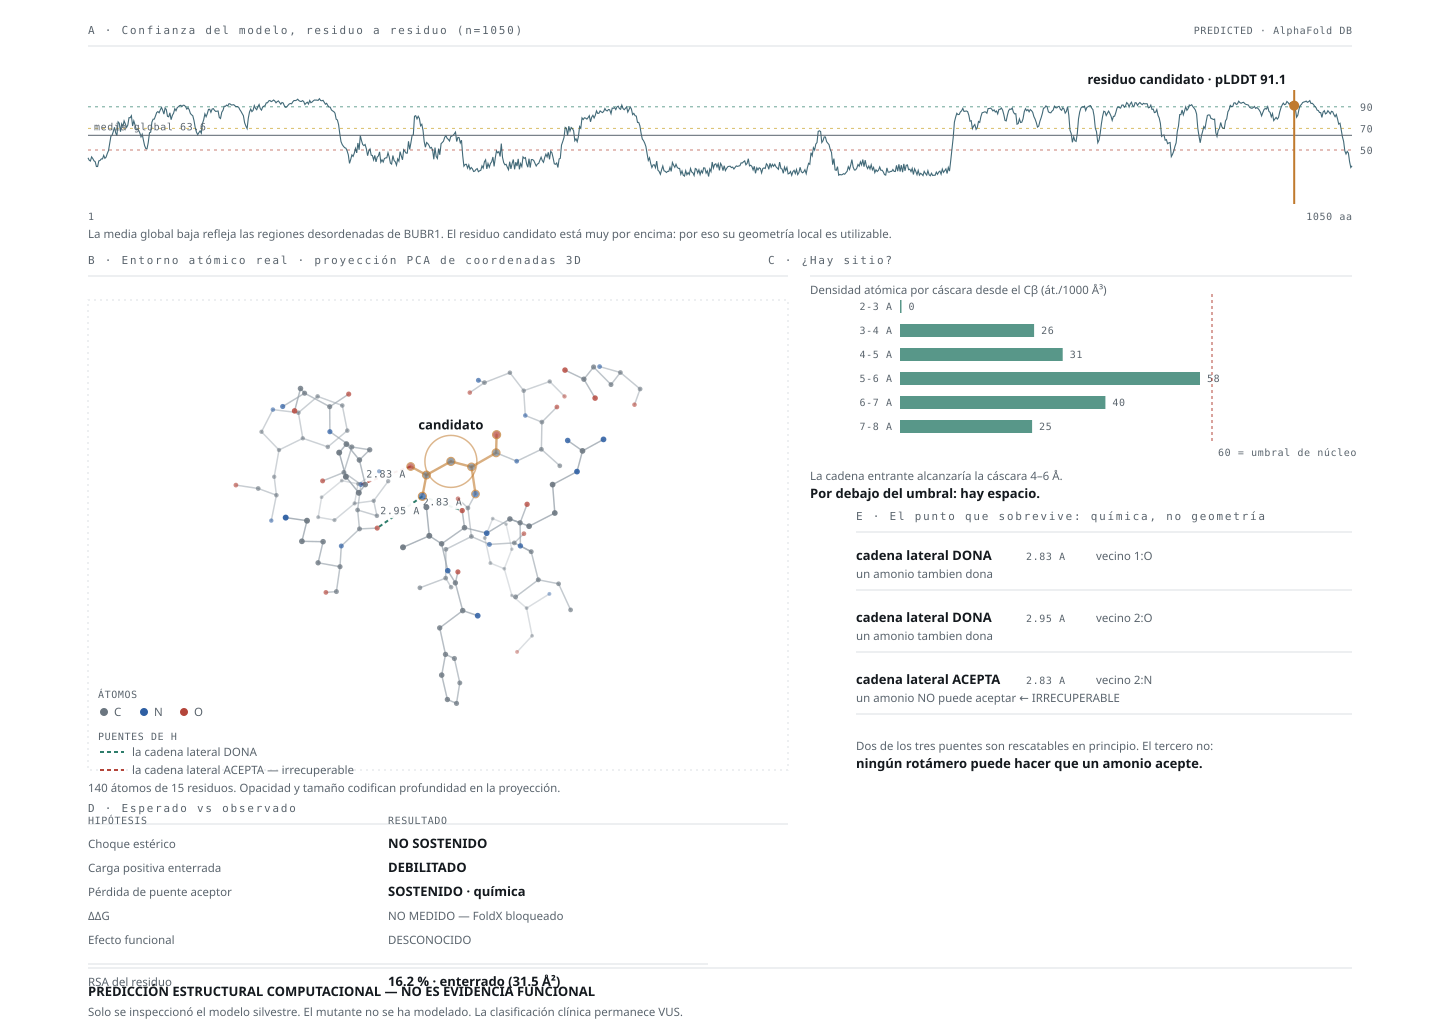

> **Figura principal 1 · interrogatorio estructural**  
> `EXP-010` · **PREDICTED**  
> *Qué enseña:* coordenadas atomicas reales proyectadas por PCA, los tres puentes de hidrogeno con sus distancias medidas, y el perfil de pLDDT. El residuo esta enterrado (RSA 16,2 %) en un entorno hidrofobico, y su cadena lateral grapa la conformacion local.  
> **Qué NO demuestra:** que la sustitucion desestabilice. Todo lo medido es sobre el modelo SILVESTRE; el mutante NO se ha modelado. El argumento esterico y el de carga enterrada quedaron DEBILITADOS: hay sitio y hay salida al solvente. Lo que sobrevive es la perdida rotamero-independiente de un puente ACEPTOR, que ningun rotamero puede rescatar.  
> procedencia: `src/make_fig4.py → fig4_structural.svg · sha256[:12]=3cf8d9d52005`

In [4]:
fl.svg("figures/fig4_structural.svg",
       "Figura principal 1 · interrogatorio estructural",
       "EXP-010", "PREDICTED",
       "coordenadas atomicas reales proyectadas por PCA, los tres puentes de hidrogeno con "
       "sus distancias medidas, y el perfil de pLDDT. El residuo esta enterrado (RSA 16,2 %) "
       "en un entorno hidrofobico, y su cadena lateral grapa la conformacion local.",
       "que la sustitucion desestabilice. Todo lo medido es sobre el modelo SILVESTRE; el "
       "mutante NO se ha modelado. El argumento esterico y el de carga enterrada quedaron "
       "DEBILITADOS: hay sitio y hay salida al solvente. Lo que sobrevive es la perdida "
       "rotamero-independiente de un puente ACEPTOR, que ningun rotamero puede rescatar.",
       generator="src/make_fig4.py")

## Resultado primario 2 · conservación ortóloga

Un porcentaje de identidad suelto es ininterpretable. Hacen falta tres controles: **línea base
interna**, **cobertura comparable** y **desglose por clado** — porque 120 ortólogos no son 120
observaciones independientes.

In [5]:
c = json.load(io.open("work/conservation/conservation_full.json", encoding="utf-8"))
cand, cc = c["candidate"], c["coverage_comparable"]
print(f"  ortologos 1:1                       : {c['n_orthologs_one2one']}")
print(f"  identidad en la posicion candidata  : {cand['identity_pct']} %")
print(f"  mediana de toda la proteina         : {c['baseline']['median_identity_pct']} %")
print(f"  percentil (cobertura comparable)    : {cc['candidate_percentile']}")
print(f"  capacidad ACEPTORA conservada       : {cand['acceptor_pct']} %")
print()
print("  por clado:")
for r in c["by_clade"]:
    acc = f"{r['acceptor_pct']:.0f} %" if r["acceptor_pct"] is not None else "  —"
    print(f"    {r['clade']:<26} {r['n_aligned']:>3}/{r['n_species']:<3} alinean · aceptor {acc}")

  ortologos 1:1                       : 153
  identidad en la posicion candidata  : 96.67 %
  mediana de toda la proteina         : 74.78 %
  percentil (cobertura comparable)    : 92.7
  capacidad ACEPTORA conservada       : 99.2 %

  por clado:
    primates                    23/23  alinean · aceptor 100 %
    otros mamiferos             67/68  alinean · aceptor 100 %
    aves                        12/13  alinean · aceptor 92 %
    reptiles                    12/13  alinean · aceptor 100 %
    anfibios                     2/2   alinean · aceptor 100 %
    peces con aleta radiada      4/33  alinean · aceptor 100 %
    vertebrados basales          0/1   alinean · aceptor   —


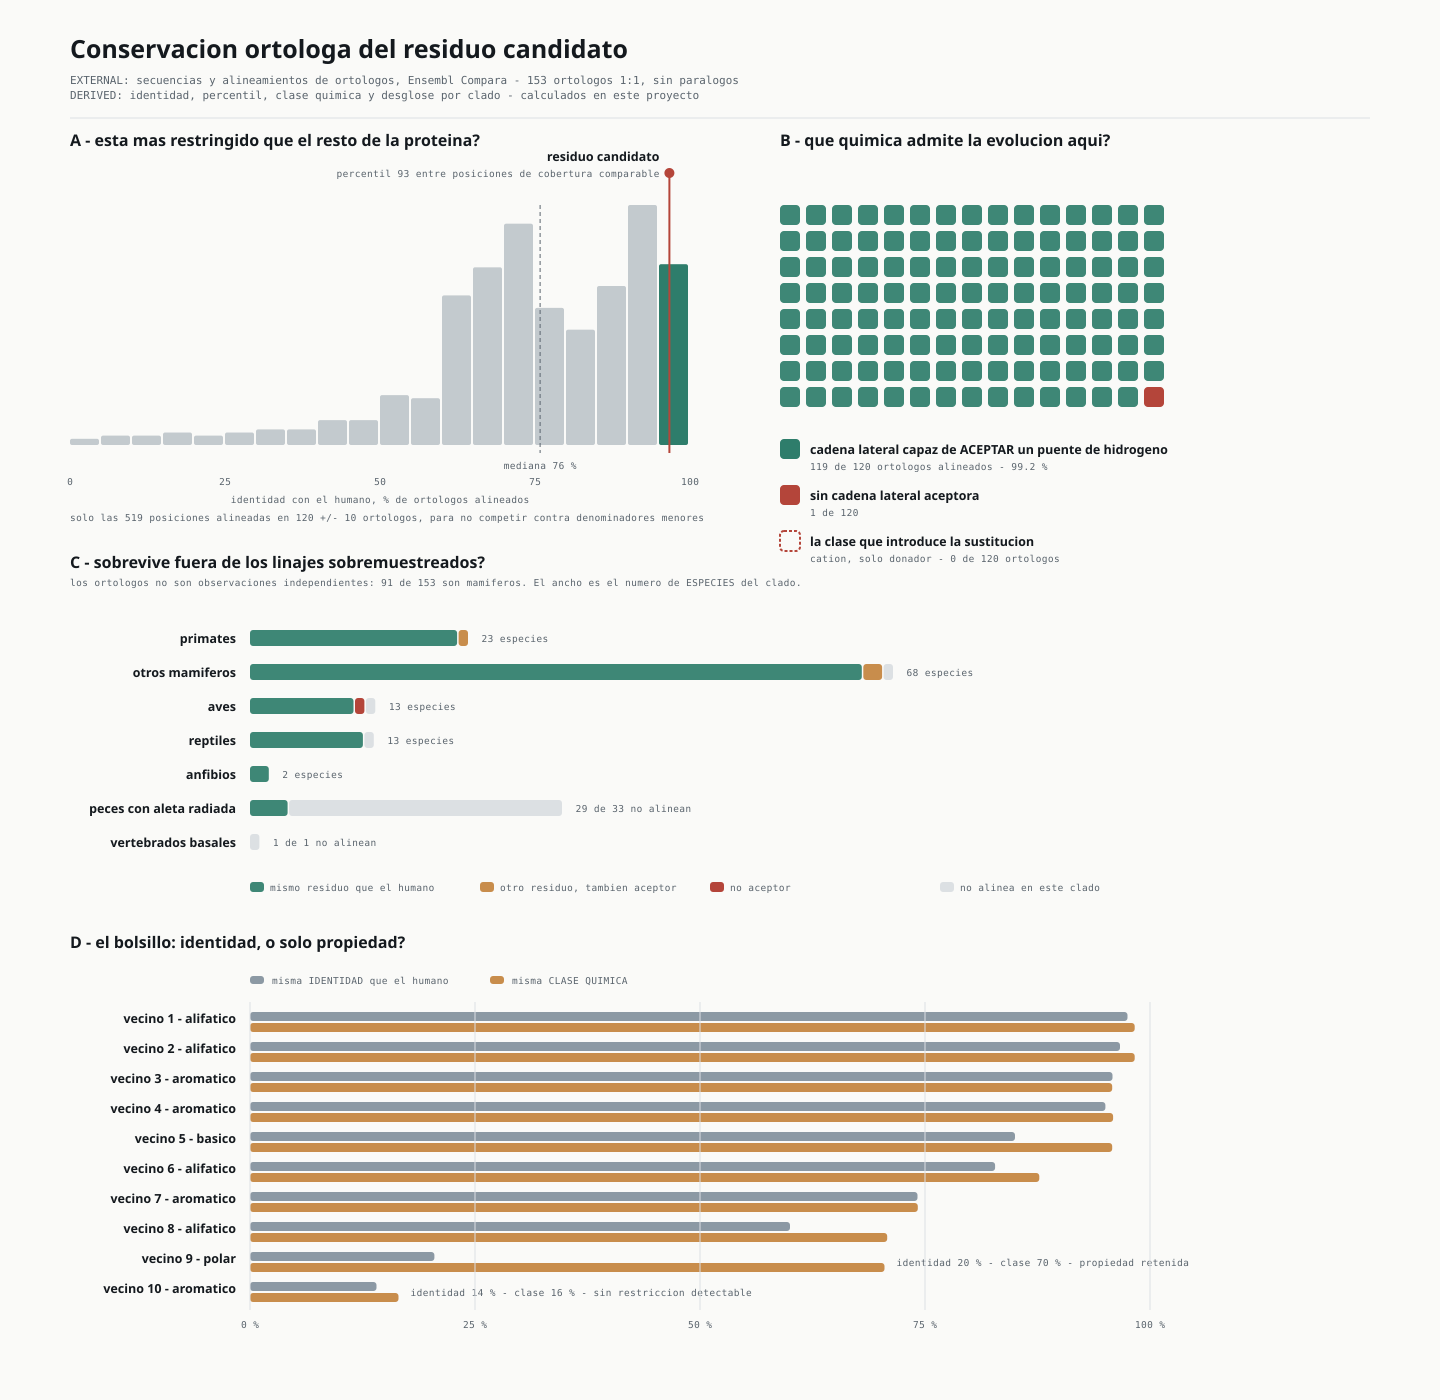

> **Figura principal 2 · conservacion ortologa con sus tres controles**  
> `EXP-011` · **EXTERNAL+DERIVED**  
> *Qué enseña:* la posicion esta en el percentil 92.7 de su PROPIA proteina entre posiciones de cobertura comparable. La restriccion es quimica antes que de identidad: 99.2 % de los ortologos alineados conservan una cadena capaz de ACEPTAR un puente de hidrogeno, y la clase cationica que introduce la sustitucion no aparece en NINGUNO.  
> **Qué NO demuestra:** conservacion en todos los vertebrados: en peces solo alinean 4 de 33 y en basales ninguno. Las observaciones efectivamente independientes son ~5-6 a nivel de clado, no 120. Y NO reabre PP3.  
> procedencia: `src/make_fig7.py → fig7_conservation.svg · sha256[:12]=dda1c58d707b`

In [6]:
fl.svg("figures/fig7_conservation.svg",
       "Figura principal 2 · conservacion ortologa con sus tres controles",
       "EXP-011", "EXTERNAL+DERIVED",
       f"la posicion esta en el percentil {cc['candidate_percentile']} de su PROPIA proteina "
       f"entre posiciones de cobertura comparable. La restriccion es quimica antes que de "
       f"identidad: {cand['acceptor_pct']} % de los ortologos alineados conservan una cadena "
       "capaz de ACEPTAR un puente de hidrogeno, y la clase cationica que introduce la "
       "sustitucion no aparece en NINGUNO.",
       "conservacion en todos los vertebrados: en peces solo alinean 4 de 33 y en basales "
       "ninguno. Las observaciones efectivamente independientes son ~5-6 a nivel de clado, "
       "no 120. Y NO reabre PP3.",
       generator="src/make_fig7.py")

### La sorpresa: esto falsó una explicación del propio proyecto

`docs/STRUCTURAL_MISSENSE.md` justificaba la discrepancia con REVEL diciendo que *«un residuo
puede ser estructuralmente crítico y aun así no estar profundamente conservado»*.

**Está conservado.** La explicación queda falsada, se conservó el texto original con la
anotación, y **la discrepancia con REVEL queda sin explicar y es más llamativa que antes**.

## Robustez · qué movería el missense, y qué no

El missense no se mueve por más predictores. Solo por dos cosas.

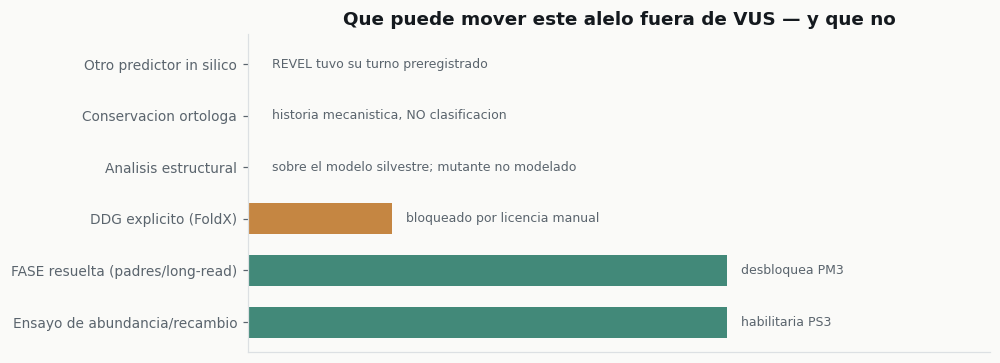

> **Figura de robustez · los unicos dos caminos que quedan**  
> `EXP-007 · EXP-011b` · **DERIVED**  
> *Qué enseña:* acumular mas evidencia in silico no cambia la clasificacion: el techo con PM1+PM5 son 5 puntos y VUS llega hasta 5. Solo la FASE (via PM3) o EVIDENCIA FUNCIONAL (via PS3) mueven este alelo.  
> **Qué NO demuestra:** que esos dos caminos vayan a resolverlo a favor. Un ensayo de abundancia que salga plano mataria la rama, y ese es exactamente el trato: se aceptaria igual que se acepto REVEL indeterminado.  
> procedencia: `marco bayesiano de ClinGen aplicado en EXP-007`

In [7]:
PATHS = [
    ("Otro predictor in silico",        0.0, "REVEL tuvo su turno preregistrado", fl.DEAD),
    ("Conservacion ortologa",           0.0, "historia mecanistica, NO clasificacion", fl.DEAD),
    ("Analisis estructural",            0.0, "sobre el modelo silvestre; mutante no modelado", fl.DEAD),
    ("DDG explicito (FoldX)",           0.3, "bloqueado por licencia manual", fl.OPEN),
    ("FASE resuelta (padres/long-read)", 1.0, "desbloquea PM3", fl.ALIVE),
    ("Ensayo de abundancia/recambio",   1.0, "habilitaria PS3", fl.ALIVE),
]
fig, ax = plt.subplots(figsize=(9.2, 3.4))
names = [p[0] for p in PATHS][::-1]
vals = [p[1] for p in PATHS][::-1]
notes = [p[2] for p in PATHS][::-1]
cols = [p[3] for p in PATHS][::-1]
ax.barh(range(len(names)), vals, color=cols, alpha=0.9, height=0.6)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=9)
ax.set_xlim(0, 1.55); ax.set_xticks([])
for i, n in enumerate(notes):
    ax.text(max(vals[i], 0.02) + 0.03, i, n, va="center", fontsize=8.2, color=fl.SOFT)
ax.set_title("Que puede mover este alelo fuera de VUS — y que no")
ax.grid(False)

fl.done(fig, "Figura de robustez · los unicos dos caminos que quedan", "EXP-007 · EXP-011b",
        "DERIVED",
        "acumular mas evidencia in silico no cambia la clasificacion: el techo con PM1+PM5 "
        "son 5 puntos y VUS llega hasta 5. Solo la FASE (via PM3) o EVIDENCIA FUNCIONAL "
        "(via PS3) mueven este alelo.",
        "que esos dos caminos vayan a resolverlo a favor. Un ensayo de abundancia que salga "
        "plano mataria la rama, y ese es exactamente el trato: se aceptaria igual que se "
        "acepto REVEL indeterminado.",
        prov="marco bayesiano de ClinGen aplicado en EXP-007")

## Decisión

| | |
|---|---|
| **Estructura** | Residuo enterrado en región de alta confianza; pérdida rotámero-independiente de un puente aceptor. **Estructuralmente preocupante** |
| **Conservación** | **SURVIVES** — percentil 93, restricción química al 99,2 %, clase entrante en 0 de 120 |
| **Clasificación** | **Sin cambios: VUS** |
| **Efecto en ACMG** | **Ninguno** |

**La formulación defendible:** *structurally concerning and evolutionarily constrained;
destabilization has not been demonstrated.*

### Qué NO demuestra

No demuestra desestabilización · no restaura `PP3` · no establece patogenicidad · el bolsillo
es hidrofóbico conservado pero **la «jaula de cuatro aromáticos» no lo está** — uno de los
cuatro no se conserva ni en identidad ni en clase.

### Falsificador

Un ΔΔG explícito próximo a cero con repeticiones convergentes; o un ortólogo funcional con
catión en esa posición.

### Siguiente experimento

**Ensayo de abundancia y recambio de BUBR1 específico de variante** (`EXP-011b`). Es lo único
que resuelve la incertidumbre que ni la secuencia ni la estructura estática pueden tocar. **No
lo ejecuta este proyecto**; se registra porque cada rama debe terminar diciendo qué experimento
reduciría más la incertidumbre.